# 03 - Extracting and Ranking Handcrafted Features

**Goal:** Find out whether the handcrafted audio features from `src/features.py` carry meaningful real/fake information on the external `garystafford/deepfake-audio-detection` dataset.

**Scope:** This is an exploratory check. `requirements.txt` and `README.md` are intentionally left unchanged. `datasets` is installed ad hoc for this run only.

*Note:* This notebook uses only the project's handcrafted features. The wav2vec2 preprocessing step is not needed to answer this question.

## Contents

1. Setup
2. Loading the External Dataset
3. Extracting the Handcrafted Features
4. Checking for Obvious Shortcuts
5. Ranking the Features
6. Results
7. Summary

## Setup

Loads the project code, the dataset tools, and the scoring/importance helpers. Audio settings come from `src/config.py` so the trimming and clip length match the rest of the project.

In [1]:
# Re-import edited files from src/ automatically, and show plots inside the notebook
%load_ext autoreload
%autoreload 2
%matplotlib inline

# Let the notebook import our shared code from src/
import sys
sys.path.insert(0, "../src")

import io
import re
import warnings
from pathlib import Path

import datasets
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import soundfile as sf
from datasets import Audio, load_dataset
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

from config import CLIP_SECONDS, FEATURES_DIR, N_LFCC, N_MELS, N_MFCC, SAMPLE_RATE, TRIM_TOP_DB
from features import FEATURES

REAL, FAKE = 0, 1
NAMES = {REAL: "real", FAKE: "fake"}
COLORS = {REAL: "tab:blue", FAKE: "tab:red"}

print(f"datasets {datasets.__version__} | scikit-learn {sklearn.__version__}")
print(f"clip length {CLIP_SECONDS:g}s | sample rate {SAMPLE_RATE:,} Hz | trim {TRIM_TOP_DB} dB")

datasets 5.1.0 | scikit-learn 1.9.1
clip length 4s | sample rate 16,000 Hz | trim 30 dB


## Loading the External Dataset

The dataset has one split with 1,866 clips, balanced 933 real and 933 fake. `decode=False` keeps the raw FLAC bytes so the notebook can control resampling and channel handling explicitly.

This matters here: the real files are **44.1 kHz stereo** YouTube audio, while the fake files are **16 kHz mono**. That difference on its own would separate the labels perfectly, so every clip is converted to 16 kHz mono before any feature is computed.

In [2]:
dataset = load_dataset("garystafford/deepfake-audio-detection", split="train")
dataset = dataset.cast_column("audio", Audio(decode=False))

labels = np.array(dataset["label"])
print(dataset)
print(dataset.features)
print(f"real: {(labels == REAL).sum():,} | fake: {(labels == FAKE).sum():,}")
print("example paths:", [a["path"] for a in dataset["audio"][:3]])

Dataset({
    features: ['audio', 'label'],
    num_rows: 1866
})
{'audio': Audio(sampling_rate=None, decode=False, num_channels=None, stream_index=None), 'label': ClassLabel(names=['real', 'fake'])}
real: 933 | fake: 933
example paths: ['yt_0000_p2_part_167.flac', 'yt_0000_part_001.flac', 'yt_0000_part_002.flac']


## Extracting the Handcrafted Features

Each clip is:

1. decoded from the FLAC bytes,
2. mixed down to mono if needed,
3. resampled to 16 kHz,
4. trimmed of leading/trailing silence with the project's `TRIM_TOP_DB`,
5. repeated or cut to the project's `CLIP_SECONDS` length.

The eight feature groups are then computed with `src/features.py`. Frame-based features are summarized by their mean and standard deviation over time, exactly as in notebook 02. Pitch also gets a voiced fraction.

Results are cached under `features/hf_deepfake/` so the notebook can be re-run without extracting everything again.

In [3]:
ROW_NAMES = {
    "mfcc": [f"{p}mfcc{i}" for p in ("", "d_", "dd_") for i in range(N_MFCC)],
    "lfcc": [f"lfcc{i}" for i in range(N_LFCC)],
    "logmel": [f"logmel{i}" for i in range(N_MELS)],
    "cqt": [f"cqt{i}" for i in range(84)],
    "spectral": ["centroid", "flatness", "rolloff", "flux"],
    "pitch": ["f0", "voiced_prob"],
    "jitter_shimmer": ["jitter", "shimmer"],
    "noise": ["noise_mean_db", "noise_std_db"],
}


def summarize_one(feature, x):
    """One dict of named numbers for one clip, matching notebook 02."""
    names = ROW_NAMES[feature]
    if x.ndim == 1:  # already one number per clip
        return {f"{feature}:{n}": float(v) for n, v in zip(names, x)}

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # pitch is NaN where there is no pitch
        mean, std = np.nanmean(x, axis=1), np.nanstd(x, axis=1)

    cols = {}
    for i, n in enumerate(names):
        cols[f"{feature}:{n}:mean"] = float(mean[i])
        cols[f"{feature}:{n}:std"] = float(std[i])
    if feature == "pitch":
        cols["pitch:voiced_fraction"] = float(np.mean(~np.isnan(x[0])))
    return cols


def prepare_audio(audio, seconds=CLIP_SECONDS):
    """Decode, downmix, resample, trim, and fit to the project clip length."""
    raw, sr = sf.read(io.BytesIO(audio["bytes"]), dtype="float32", always_2d=True)
    channels = raw.shape[1]
    original_duration = len(raw) / sr

    y = raw.mean(axis=1) if channels > 1 else raw[:, 0]
    if sr != SAMPLE_RATE:
        y = librosa.resample(y, orig_sr=sr, target_sr=SAMPLE_RATE)
    y, _ = librosa.effects.trim(y, top_db=TRIM_TOP_DB)
    y = np.resize(y, int(seconds * SAMPLE_RATE))
    return y, sr, channels, original_duration


def source_group(path):
    """Use the source/video/TTS identifier part of the filename as the group."""
    match = re.match(r"([a-z]{2}_\d+)", Path(path).name)
    return match.group(1) if match else Path(path).stem


CACHE_DIR = FEATURES_DIR / "hf_deepfake" / f"{CLIP_SECONDS:g}s_handcrafted"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY_PATH = CACHE_DIR / "summary.csv"
META_PATH = CACHE_DIR / "meta.csv"
RECOMPUTE = False

if SUMMARY_PATH.exists() and META_PATH.exists() and not RECOMPUTE:
    summary = pd.read_csv(SUMMARY_PATH)
    meta = pd.read_csv(META_PATH)
    print(f"loaded cached features from {CACHE_DIR}")
else:
    rows, meta_rows = [], []
    for i in tqdm(range(len(dataset)), desc="extracting features"):
        row = dataset[i]
        audio = row["audio"]
        y, original_sr, channels, original_duration = prepare_audio(audio)

        features = {}
        for feature in FEATURES:
            features.update(summarize_one(feature, FEATURES[feature][0](y)))
        rows.append(features)
        meta_rows.append({
            "path": audio["path"],
            "group": source_group(audio["path"]),
            "label": int(row["label"]),
            "original_sr": original_sr,
            "channels": channels,
            "original_duration_s": original_duration,
        })

    summary = pd.DataFrame(rows).astype(np.float32)
    meta = pd.DataFrame(meta_rows)
    summary.to_csv(SUMMARY_PATH, index=False)
    meta.to_csv(META_PATH, index=False)
    print(f"saved features to {CACHE_DIR}")

print(f"summary: {summary.shape[0]:,} clips x {summary.shape[1]} numbers")
print(f"groups: {meta['group'].nunique()} | real groups: {meta.loc[meta.label == REAL, 'group'].nunique()} | fake groups: {meta.loc[meta.label == FAKE, 'group'].nunique()}")

loaded cached features from /home/jackm/VishingDetector/features/hf_deepfake/4s_handcrafted
summary: 1,866 clips x 505 numbers
groups: 110 | real groups: 14 | fake groups: 96


## Checking for Obvious Shortcuts

Before ranking anything, check whether the original recording format itself gives the label away. If it does, the resampling step above is essential; otherwise the ranking would just rediscover the file format.

In [4]:
format_counts = pd.crosstab(
    [meta["original_sr"], meta["channels"]], meta["label"]
).rename(columns=NAMES)
format_counts.index.names = ["original sample rate", "channels"]
format_counts

,label,real,fake
original sample rate,channels,,
16000,1,0,933
44100,2,933,0


In [5]:
duration = meta.groupby("label")["original_duration_s"].describe().rename(index=NAMES).round(2)
duration

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
real,933.0,4.72,1.85,2.5,3.22,4.16,6.00,12.53
fake,933.0,3.68,1.04,2.5,2.95,3.38,4.13,11.57


## Ranking the Features

The dataset has only one split, so the notebook creates its own validation folds. It uses **group-aware** folds when possible, so clips from the same YouTube video or TTS voice are not split across train and validation. If a fold cannot contain both classes, it falls back to ordinary stratified folds and says so.

Four rankings are computed:

- **Univariate AUC:** how well one number separates real from fake on its own, with the direction learned on the training fold and checked on the validation fold.
- **Mutual information:** how much one number tells us about the label, allowing non-linear relationships.
- **Logistic-regression coefficients:** which numbers the model weights most strongly. Correlated features can share or hide importance.
- **Permutation importance:** how much validation AUC drops when a number is shuffled. This is also aggregated by feature group, which is more reliable for correlated features.

A shuffled-label baseline is included so the best real score can be compared with what chance alone produces.

In [6]:
y = meta["label"].to_numpy()
groups = meta["group"].to_numpy()
feature_names = summary.columns.tolist()
feature_groups = {g: [c for c in feature_names if c.split(":")[0] == g] for g in FEATURES}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
folds = list(cv.split(summary, y, groups))
split_name = "group-aware"
if any(len(np.unique(y[tr])) < 2 or len(np.unique(y[te])) < 2 for tr, te in folds):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    folds = list(cv.split(summary, y))
    split_name = "stratified"

print(f"using {split_name} 5-fold validation")
for k, (tr, te) in enumerate(folds):
    print(f"  fold {k}: train {len(tr):,} | validation {len(te):,} | train labels {np.bincount(y[tr])} | validation labels {np.bincount(y[te])}")


def univariate_aucs(X, y):
    """ROC-AUC per column, ignoring non-finite values."""
    out = {}
    for col in X.columns:
        v = X[col].to_numpy()
        ok = np.isfinite(v)
        if ok.sum() and len(np.unique(y[ok])) == 2:
            out[col] = roc_auc_score(y[ok], v[ok])
    return pd.Series(out, dtype=float)


def make_pipeline():
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("logreg", LogisticRegression(max_iter=3000, class_weight="balanced")),
    ])


N_PERM_REPEATS = 3
N_GROUP_REPEATS = 5
N_NULL_MODEL_REPEATS = 5
N_NULL_SELECT_REPEATS = 20

records = []
group_records = []
fold_model_aucs = []
rng = np.random.default_rng(0)

for k, (tr, te) in enumerate(folds):
    print(f"fold {k}/{len(folds) - 1}: scoring {len(feature_names)} numbers ...")
    X_train, X_validation = summary.iloc[tr], summary.iloc[te]
    y_train, y_validation = y[tr], y[te]

    auc_train = univariate_aucs(X_train, y_train)
    auc_validation = univariate_aucs(X_validation, y_validation)

    imputer = SimpleImputer(strategy="median")
    X_train_imputed = imputer.fit_transform(X_train)
    X_validation_imputed = imputer.transform(X_validation)
    mi = pd.Series(
        mutual_info_classif(X_train_imputed, y_train, random_state=0),
        index=feature_names,
    )

    pipeline = make_pipeline()
    pipeline.fit(X_train, y_train)
    model_auc = roc_auc_score(y_validation, pipeline.predict_proba(X_validation)[:, 1])
    fold_model_aucs.append(model_auc)

    perm = permutation_importance(
        pipeline, X_validation, y_validation,
        scoring="roc_auc", n_repeats=N_PERM_REPEATS, random_state=0, n_jobs=-1,
    )
    perm_importance = pd.Series(perm.importances_mean, index=feature_names)
    coefficients = pd.Series(pipeline.named_steps["logreg"].coef_[0], index=feature_names)

    for col in feature_names:
        train_auc = auc_train.get(col, np.nan)
        validation_auc = auc_validation.get(col, np.nan)
        direction = 1 if (not np.isfinite(train_auc) or train_auc >= 0.5) else -1
        validation_aligned = validation_auc if direction == 1 else 1 - validation_auc
        records.append({
            "fold": k,
            "feature": col,
            "group": col.split(":")[0],
            "auc_train": train_auc,
            "auc_validation_aligned": validation_aligned,
            "mutual_information": mi[col],
            "coefficient": coefficients[col],
            "permutation_importance": perm_importance[col],
            "model_auc": model_auc,
        })

    for group, columns in feature_groups.items():
        drops = []
        for _ in range(N_GROUP_REPEATS):
            shuffled = X_validation.copy()
            order = rng.permutation(len(shuffled))
            shuffled[columns] = shuffled[columns].to_numpy()[order]
            score = roc_auc_score(y_validation, pipeline.predict_proba(shuffled)[:, 1])
            drops.append(model_auc - score)
        group_records.append({"fold": k, "group": group, "importance": float(np.mean(drops))})

fold_results = pd.DataFrame(records)

ranking = fold_results.groupby(["feature", "group"]).agg(
    auc_train_mean=("auc_train", "mean"),
    auc_train_std=("auc_train", "std"),
    auc_validation_mean=("auc_validation_aligned", "mean"),
    auc_validation_std=("auc_validation_aligned", "std"),
    mutual_information_mean=("mutual_information", "mean"),
    mutual_information_std=("mutual_information", "std"),
    coefficient_mean=("coefficient", "mean"),
    coefficient_std=("coefficient", "std"),
    permutation_mean=("permutation_importance", "mean"),
    permutation_std=("permutation_importance", "std"),
).reset_index()
ranking["separation_train"] = 0.5 + (ranking["auc_train_mean"] - 0.5).abs()
ranking["absolute_coefficient"] = ranking["coefficient_mean"].abs()
ranking["permutation_rank"] = ranking["permutation_mean"].rank(ascending=False).astype(int)

group_ranking = (
    pd.DataFrame(group_records)
    .groupby("group")["importance"]
    .agg(importance_mean="mean", importance_std="std")
    .reindex(list(FEATURES))
    .sort_values("importance_mean", ascending=False)
)

ranking.to_csv(CACHE_DIR / "ranking.csv", index=False)
group_ranking.to_csv(CACHE_DIR / "group_ranking.csv")
print("saved ranking tables")
print(f"model AUC per fold: {np.round(fold_model_aucs, 3).tolist()} | mean {np.mean(fold_model_aucs):.3f}")

using group-aware 5-fold validation
  fold 0: train 1,501 | validation 365 | train labels [755 746] | validation labels [178 187]
  fold 1: train 1,488 | validation 378 | train labels [741 747] | validation labels [192 186]
  fold 2: train 1,492 | validation 374 | train labels [746 746] | validation labels [187 187]
  fold 3: train 1,490 | validation 376 | train labels [743 747] | validation labels [190 186]
  fold 4: train 1,493 | validation 373 | train labels [747 746] | validation labels [186 187]
fold 0/4: scoring 505 numbers ...


fold 1/4: scoring 505 numbers ...


fold 2/4: scoring 505 numbers ...


fold 3/4: scoring 505 numbers ...


fold 4/4: scoring 505 numbers ...


saved ranking tables
model AUC per fold: [1.0, 0.923, 1.0, 1.0, 1.0] | mean 0.985


### Shuffled-label baseline

The same folds are scored with shuffled training labels. This shows what the model and the selection procedure produce when there is no real signal.

In [7]:
rng = np.random.default_rng(1)

null_model_aucs = []
for rep in range(N_NULL_MODEL_REPEATS):
    scores = []
    for tr, te in folds:
        y_shuffled = rng.permutation(y[tr])
        pipeline = make_pipeline()
        pipeline.fit(summary.iloc[tr], y_shuffled)
        scores.append(roc_auc_score(y[te], pipeline.predict_proba(summary.iloc[te])[:, 1]))
    null_model_aucs.append(float(np.mean(scores)))

real_selected_aucs = []
for tr, te in folds:
    auc_train = univariate_aucs(summary.iloc[tr], y[tr])
    best = (0.5 + (auc_train - 0.5).abs()).idxmax()
    v = summary.iloc[te][best].to_numpy()
    ok = np.isfinite(v)
    score = roc_auc_score(y[te][ok], v[ok])
    if auc_train[best] < 0.5:
        score = 1 - score
    real_selected_aucs.append(score)

null_selected_aucs = []
for rep in range(N_NULL_SELECT_REPEATS):
    y_shuffled = rng.permutation(y)
    scores = []
    for tr, te in folds:
        auc_train = univariate_aucs(summary.iloc[tr], y_shuffled[tr])
        best = (0.5 + (auc_train - 0.5).abs()).idxmax()
        v = summary.iloc[te][best].to_numpy()
        ok = np.isfinite(v)
        score = roc_auc_score(y[te][ok], v[ok])
        if auc_train[best] < 0.5:
            score = 1 - score
        scores.append(score)
    null_selected_aucs.append(float(np.mean(scores)))

baseline = pd.DataFrame({
    "test": [
        "logistic model, real labels",
        "logistic model, shuffled train labels",
        "best single feature, real labels",
        "best single feature, shuffled labels",
    ],
    "mean_auc": [
        float(np.mean(fold_model_aucs)),
        float(np.mean(null_model_aucs)),
        float(np.mean(real_selected_aucs)),
        float(np.mean(null_selected_aucs)),
    ],
    "std": [
        float(np.std(fold_model_aucs)),
        float(np.std(null_model_aucs)),
        float(np.std(real_selected_aucs)),
        float(np.std(null_selected_aucs)),
    ],
})
print(f"95th percentile of chance-selected best-feature AUC: {np.percentile(null_selected_aucs, 95):.3f}")
baseline

95th percentile of chance-selected best-feature AUC: 0.660


,test,mean_auc,std
0,"logistic model, real labels",0.984535,0.030854
1,"logistic model, shuffled train labels",0.474679,0.035538
2,"best single feature, real labels",0.797500,0.166308
3,"best single feature, shuffled labels",0.505488,0.124145


## Results

### Best individual numbers by validation AUC

In [8]:
top_auc = (
    ranking.sort_values("auc_validation_mean", ascending=False)
    .head(20)[["feature", "group", "separation_train", "auc_validation_mean", "auc_validation_std", "permutation_mean"]]
    .round(3)
    .reset_index(drop=True)
)
top_auc

,feature,group,separation_train,auc_validation_mean,auc_validation_std,permutation_mean
0,cqt:cqt35:std,cqt,0.924,0.925,0.045,-0.000
1,cqt:cqt34:std,cqt,0.924,0.923,0.053,-0.000
2,cqt:cqt36:std,cqt,0.918,0.918,0.046,-0.000
3,lfcc:lfcc18:mean,lfcc,0.917,0.918,0.051,0.001
4,logmel:logmel5:std,logmel,0.922,0.917,0.064,-0.000
5,cqt:cqt33:std,cqt,0.915,0.912,0.062,-0.000
6,cqt:cqt48:std,cqt,0.906,0.908,0.031,0.000
7,cqt:cqt41:std,cqt,0.908,0.906,0.071,-0.000
8,cqt:cqt49:std,cqt,0.901,0.905,0.025,0.000
9,cqt:cqt51:std,cqt,0.901,0.905,0.040,-0.000


### Best individual numbers by permutation importance

In [9]:
top_permutation = (
    ranking.sort_values("permutation_mean", ascending=False)
    .head(20)[["feature", "group", "auc_validation_mean", "permutation_mean", "permutation_std", "coefficient_mean"]]
    .round(3)
    .reset_index(drop=True)
)
top_permutation

,feature,group,auc_validation_mean,permutation_mean,permutation_std,coefficient_mean
0,lfcc:lfcc17:mean,lfcc,0.878,0.002,0.005,-0.727
1,lfcc:lfcc16:mean,lfcc,0.904,0.002,0.003,0.731
2,lfcc:lfcc10:mean,lfcc,0.845,0.001,0.003,0.488
3,lfcc:lfcc8:mean,lfcc,0.877,0.001,0.003,0.475
4,lfcc:lfcc6:mean,lfcc,0.605,0.001,0.003,0.407
5,lfcc:lfcc18:mean,lfcc,0.918,0.001,0.002,0.549
6,mfcc:mfcc4:mean,mfcc,0.689,0.001,0.002,0.214
7,lfcc:lfcc14:mean,lfcc,0.694,0.001,0.001,0.353
8,lfcc:lfcc2:mean,lfcc,0.668,0.001,0.001,0.359
9,pitch:f0:std,pitch,0.430,0.000,0.001,-0.236


### Feature-group ranking

Group permutation importance shuffles every number in a group together, so it handles correlated features more honestly than ranking single columns.

In [10]:
group_ranking.round(4)

,importance_mean,importance_std
group,,
cqt,0.0698,0.0608
lfcc,0.0612,0.0177
mfcc,0.0009,0.0017
pitch,0.0001,0.0006
spectral,-0.0001,0.0007
jitter_shimmer,-0.0003,0.0007
noise,-0.0003,0.0007
logmel,-0.0015,0.0079


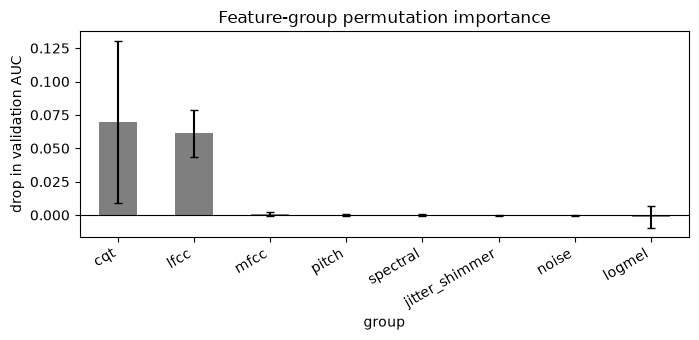

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
group_ranking["importance_mean"].plot.bar(
    yerr=group_ranking["importance_std"], ax=ax, color="tab:gray", capsize=3
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("drop in validation AUC")
ax.set_title("Feature-group permutation importance")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

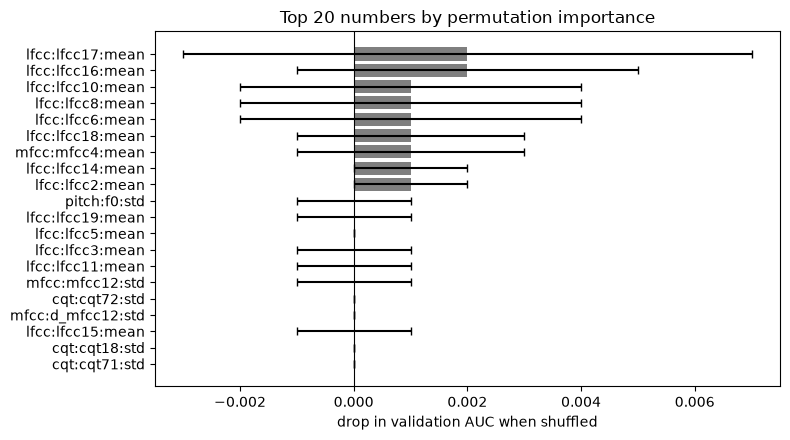

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
top = top_permutation.iloc[::-1]
ax.barh(top["feature"], top["permutation_mean"], xerr=top["permutation_std"], color="tab:gray", capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("drop in validation AUC when shuffled")
ax.set_title("Top 20 numbers by permutation importance")
plt.tight_layout()

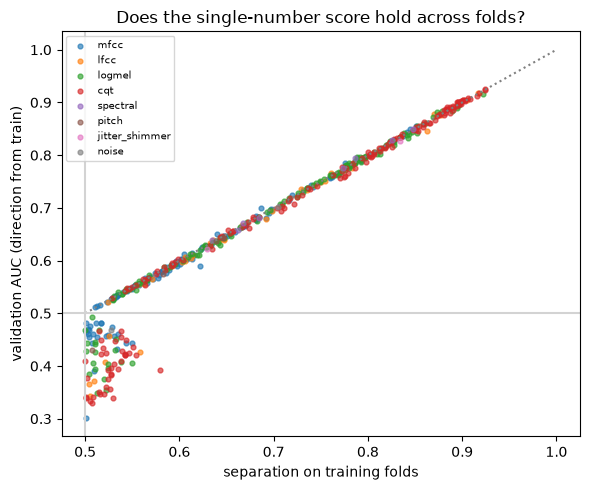

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))
for group in FEATURES:
    sub = ranking[ranking["group"] == group]
    ax.scatter(sub["separation_train"], sub["auc_validation_mean"], s=12, alpha=0.65, label=group)
ax.plot([0.5, 1], [0.5, 1], color="gray", linestyle=":")
ax.axhline(0.5, color="lightgray")
ax.axvline(0.5, color="lightgray")
ax.set_xlabel("separation on training folds")
ax.set_ylabel("validation AUC (direction from train)")
ax.set_title("Does the single-number score hold across folds?")
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout()

### Do the top numbers look like shortcuts?

The original sample rate and channel count are shown above because they separate the labels perfectly. That is a dataset artefact, not a voice property. The features below were computed after resampling to 16 kHz mono, so the ranking should not be able to use that shortcut directly. Any remaining noise/duration-like feature at the top is worth treating with suspicion.

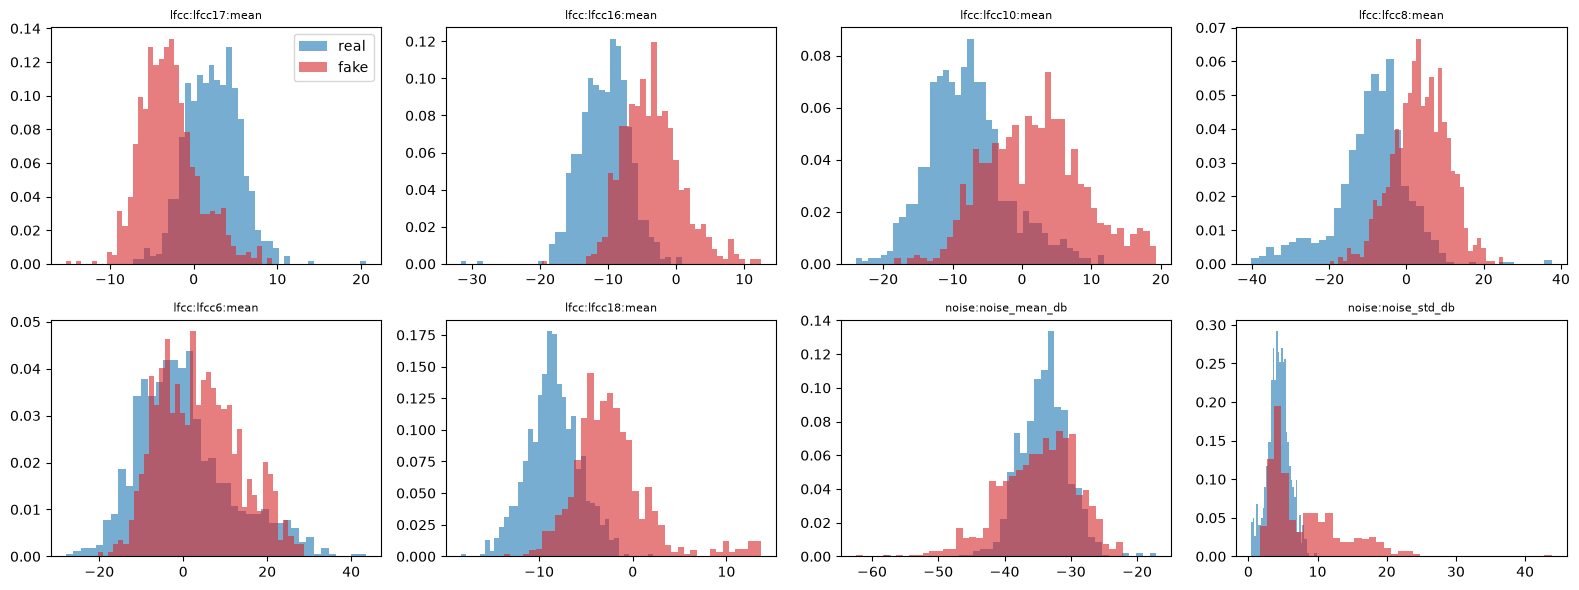

In [14]:
watch = list(dict.fromkeys(
    top_permutation["feature"].head(6).tolist()
    + ["noise:noise_mean_db", "noise:noise_std_db", "pitch:voiced_fraction"]
))

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), watch):
    for label in (REAL, FAKE):
        values = summary.loc[meta["label"] == label, col].dropna()
        ax.hist(values, bins=40, alpha=0.6, density=True, color=COLORS[label], label=NAMES[label])
    ax.set_title(col, fontsize=8)
axes[0, 0].legend()
plt.tight_layout()

## Summary

The handcrafted features carry strong, non-random signal on this dataset after removing the obvious sample-rate/channel shortcut.

- Group-aware 5-fold logistic regression: mean AUC **0.985** (folds 1.000, 0.923, 1.000, 1.000, 1.000).
- Shuffled-label model: mean AUC **0.475**, so the result is not driven by fold structure or model capacity.
- Best single feature: `cqt:cqt35:std`, validation AUC **0.925**. Best-feature selection with real labels averaged **0.798**, versus **0.505** with shuffled labels (95th percentile **0.660**).
- Group permutation importance: **CQT +0.070 AUC** and **LFCC +0.061 AUC**. Other groups are near zero or slightly negative. Individual-feature permutation scores are small because CQT/LFCC features are highly correlated and the model can substitute one for another.
- The strongest individual numbers are CQT standard deviations and LFCC means. MFCC, pitch, jitter/shimmer, noise, and spectral summaries add little once CQT/LFCC are present.

The original files are perfectly separable by sample rate and channels (44.1 kHz stereo real vs 16 kHz mono fake). The notebook resamples everything to 16 kHz mono before feature extraction, so the ranking does not use that direct shortcut. However, the dataset still confounds real YouTube audio with TTS audio, so the remaining signal may include channel, codec, or domain differences rather than only synthesis artifacts. These results justify keeping the handcrafted features, but external validation on a controlled benchmark such as ASVspoof is still needed. Wav2vec2 is not required to show that the current feature set is useful, but it may be worth trying as a stronger baseline.